# Individual Project: Predicting Online Purchases

STA 5206, Fall 2026

Name: Maria Montoya-Chang

**Question:** Can website session data be used to train a model that predicts whether a visit to an online store ends in a purchase?

**Data:** Online Shoppers Purchasing Intention Dataset, originally published on the UCI Machine Learning Repository (2018). I downloaded a copy from Kaggle: http://kaggle.com/datasets/imakash3011/online-shoppers-purchasing-intention-dataset. 12,330 rows (website sessions), 17 independent variables, and one dependent variable, Revenue (TRUE if the session ended in a purchase).

**Tools:** R, with base R, `rpart` (decision tree), and `randomForest` (random forest).


## Setup

Run this cell first. If `randomForest` is not installed yet, run `install.packages("randomForest")` once in the R console, then run this cell again.

In [1]:
library(rpart)                                # decision tree package (comes with R)
library(randomForest)                         # random forest package
options(repr.plot.width = 10, repr.plot.height = 5)   # plot size in the notebook
set.seed(5206)                                # fix the random seed so the results are the same every time

Warning message:
"package 'randomForest' was built under R version 4.3.3"
randomForest 4.7-1.2

Type rfNews() to see new features/changes/bug fixes.



## Part 1: The data

**a)** Load the data. Show the dimensions, variable types, missing values, and how many sessions ended in a purchase.

In [2]:
# Part 1(a)
shop = read.csv("data/online_shoppers_intention.csv")   # read the shoppers file
dim(shop)                                     # number of rows and columns
str(shop)                                     # variable names and types
sum(is.na(shop))                              # total number of missing values
table(Revenue = shop$Revenue)                 # number of sessions with and without a purchase
round(prop.table(table(Revenue = shop$Revenue)), 3)   # share of sessions with and without a purchase
summary(shop[, c("ProductRelated", "ProductRelated_Duration",   # summaries of key numeric variables
                 "BounceRates", "ExitRates", "PageValues")])

[1] 12330    18

'data.frame':	12330 obs. of  18 variables:
 $ Administrative         : int  0 0 0 0 0 0 0 1 0 0 ...
 $ Administrative_Duration: num  0 0 0 0 0 0 0 0 0 0 ...
 $ Informational          : int  0 0 0 0 0 0 0 0 0 0 ...
 $ Informational_Duration : num  0 0 0 0 0 0 0 0 0 0 ...
 $ ProductRelated         : int  1 2 1 2 10 19 1 0 2 3 ...
 $ ProductRelated_Duration: num  0 64 0 2.67 627.5 ...
 $ BounceRates            : num  0.2 0 0.2 0.05 0.02 ...
 $ ExitRates              : num  0.2 0.1 0.2 0.14 0.05 ...
 $ PageValues             : num  0 0 0 0 0 0 0 0 0 0 ...
 $ SpecialDay             : num  0 0 0 0 0 0 0.4 0 0.8 0.4 ...
 $ Month                  : chr  "Feb" "Feb" "Feb" "Feb" ...
 $ OperatingSystems       : int  1 2 4 3 3 2 2 1 2 2 ...
 $ Browser                : int  1 2 1 2 3 2 4 2 2 4 ...
 $ Region                 : int  1 1 9 2 1 1 3 1 2 1 ...
 $ TrafficType            : int  1 2 3 4 4 3 3 5 3 2 ...
 $ VisitorType            : chr  "Returning_Visitor" "Returning_Visitor" "Returning_Visito

[1] 0

Revenue
FALSE  TRUE 
10422  1908 

Revenue
FALSE  TRUE 
0.845 0.155 

 ProductRelated   ProductRelated_Duration  BounceRates         ExitRates      
 Min.   :  0.00   Min.   :    0.0         Min.   :0.000000   Min.   :0.00000  
 1st Qu.:  7.00   1st Qu.:  184.1         1st Qu.:0.000000   1st Qu.:0.01429  
 Median : 18.00   Median :  598.9         Median :0.003112   Median :0.02516  
 Mean   : 31.73   Mean   : 1194.8         Mean   :0.022191   Mean   :0.04307  
 3rd Qu.: 38.00   3rd Qu.: 1464.2         3rd Qu.:0.016813   3rd Qu.:0.05000  
 Max.   :705.00   Max.   :63973.5         Max.   :0.200000   Max.   :0.20000  
   PageValues     
 Min.   :  0.000  
 1st Qu.:  0.000  
 Median :  0.000  
 Mean   :  5.889  
 3rd Qu.:  0.000  
 Max.   :361.764  

The dataset has 12,330 rows and 18 columns, and each row is one visit (session) to an online store’s website.
There are no missing values.
The outcome is Revenue, which is TRUE if the session ended in a purchase and FALSE if it did not.
10,422 sessions (about 84.5%) did not end in a purchase, and 1,908 sessions (about 15.5%) did.
So the two groups are unbalanced. Most visitors leave without buying.
The other 17 columns are the predictors.
Six of them count the pages a visitor looked at and how long they spent on them, split into administrative, informational, and product pages.
BounceRates, ExitRates, and PageValues are Google Analytics measures of how visitors moved through the pages.
SpecialDay measures how close the visit was to a holiday like Mother’s Day or Valentine’s Day.
The rest describe the visit: Month, OperatingSystems, Browser, Region, TrafficType, VisitorType (new or returning), and Weekend.
Operating system, browser, region, and traffic type are stored as number codes, but they are really categories, not amounts.
The numeric variables are very skewed to the right.
For example, the median visitor looked at 18 product pages, but the mean is about 31.7 and the maximum is 705.
Time on product pages has a median of about 599 seconds but a maximum of about 63,974 seconds.
PageValues is 0 for at least 75% of sessions, since its median and third quartile are both 0, but it goes as high as about 361.8.
BounceRates and ExitRates are proportions between 0 and 0.2.

**b)** Prepare the variables. Turn the outcome into 0/1, and treat the code variables (operating system, browser, region, traffic type) and the labels (month, visitor type, weekend) as categories. Group rare categories into "Other" so every category has enough sessions.

In [3]:
# Part 1(b)
shop$buy = as.integer(shop$Revenue)           # outcome as 1 = purchase, 0 = no purchase
shop$Revenue = NULL                           # drop the original TRUE/FALSE column (now stored in buy)

lump = function(v, min_n = 50) {              # function that groups categories with fewer than 50 sessions into "Other"
  v = as.character(v)                         # treat the codes as text labels
  rare = names(which(table(v) < min_n))       # categories that are too small
  v[v %in% rare] = "Other"                    # rename the small ones to "Other"
  factor(v)                                   # return as a category variable
}
shop$OperatingSystems = lump(shop$OperatingSystems)   # operating system code as a category
shop$Browser = lump(shop$Browser)             # browser code as a category
shop$Region = lump(shop$Region)               # region code as a category
shop$TrafficType = lump(shop$TrafficType)     # traffic source code as a category
shop$VisitorType = lump(shop$VisitorType)     # new, returning, or other visitor
shop$Month = factor(shop$Month, levels = c("Feb", "Mar", "May", "June", "Jul",   # month in calendar order
                                           "Aug", "Sep", "Oct", "Nov", "Dec"))
shop$Weekend = factor(shop$Weekend)           # weekend or not, as a category
sapply(shop[, c("OperatingSystems", "Browser", "Region", "TrafficType",   # number of categories in each variable
                "VisitorType", "Month", "Weekend")], nlevels)

OperatingSystems          Browser           Region      TrafficType 
               6               10                9               12 
     VisitorType            Month          Weekend 
               3               10                2

I made a new outcome variable called buy, which is 1 if the session ended in a purchase and 0 if it did not.
Operating system, browser, region, and traffic type are stored as number codes, but the numbers are just labels, not amounts.
For example, browser 4 is not “twice” browser 2. So I treated these as categories instead of numbers.
I also treated Month, VisitorType, and Weekend as categories.
Some categories had very few sessions, which can make the models unstable and cause problems when a category shows up in the testing data but not in the training data.
So I grouped every category with fewer than 50 sessions into a single “Other” group.
Operating system went from 8 codes to 6 groups, after combining 3 small codes with 32 sessions in total.
Browser went from 13 codes to 10 groups, after combining 4 small codes with 66 sessions.
Traffic type went from 20 codes to 12 groups, after combining 9 small codes with 165 sessions.
Region kept all 9 codes, since every region had at least 50 sessions.
Visitor type has 3 groups: new visitor, returning visitor, and other.
Month has 10 groups, since the data has no sessions in January or April.
Weekend has 2 groups, weekend or not.
I put the months in calendar order so the plots and tables are easier to read.

**c)** Plot the data. Show how often each group buys, and how key variables differ between sessions with and without a purchase.

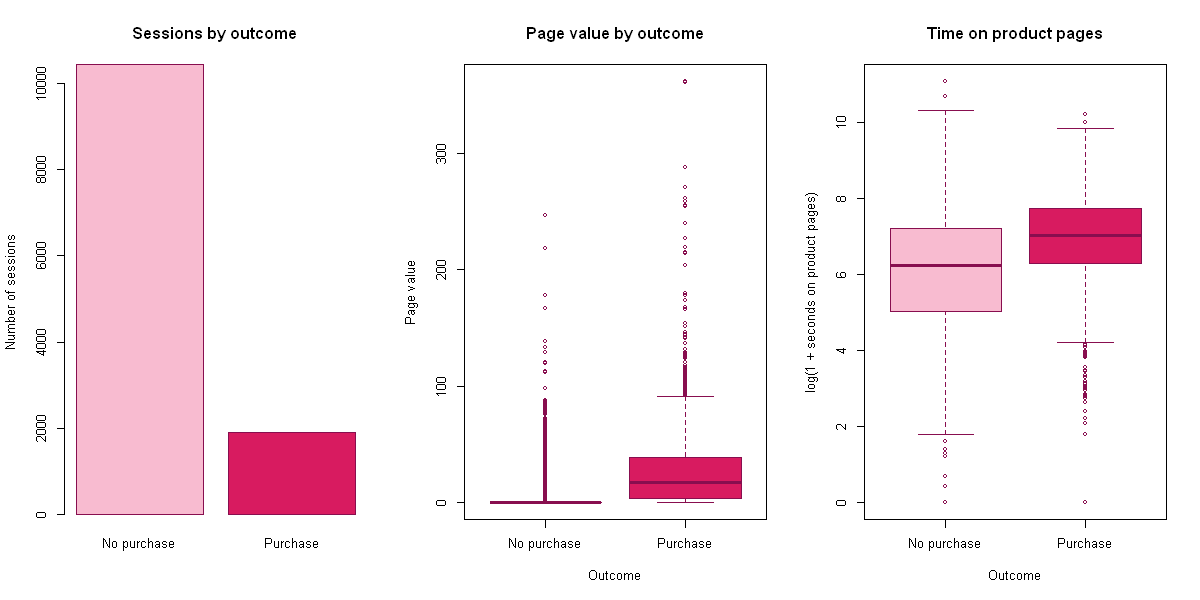

Feb   Mar   May  June   Jul   Aug   Sep   Oct   Nov   Dec 
0.016 0.101 0.109 0.101 0.153 0.176 0.192 0.209 0.254 0.125

New_Visitor             Other Returning_Visitor 
            0.249             0.188             0.139

buy,ProductRelated,ExitRates,PageValues
<int>,<dbl>,<dbl>,<dbl>
0,16,0.02857143,0.00000
1,29,0.01600000,16.75813


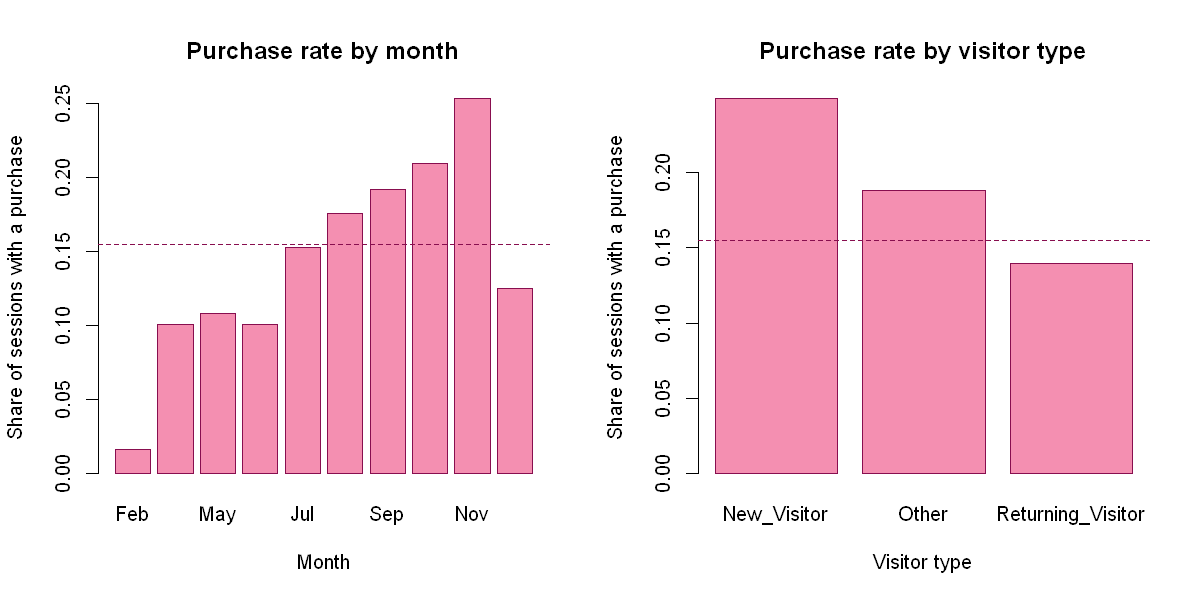

In [4]:
# Part 1(c)
par(mfrow = c(1, 3))                          # three plots side by side
barplot(table(shop$buy), names.arg = c("No purchase", "Purchase"),   # bar chart of the outcome
        col = c("#F8BBD0", "#D81B60"), border = "#880E4F",            # pink bar colors and outline
        ylab = "Number of sessions", main = "Sessions by outcome")    # axis label and title
boxplot(PageValues ~ buy, data = shop, names = c("No purchase", "Purchase"),   # page value by outcome
        col = c("#F8BBD0", "#D81B60"), border = "#880E4F",            # pink box colors and outline
        xlab = "Outcome", ylab = "Page value", main = "Page value by outcome")   # axis labels and title
boxplot(log1p(ProductRelated_Duration) ~ buy, data = shop,   # time on product pages by outcome (log scale)
        names = c("No purchase", "Purchase"),                 # labels for the two groups
        col = c("#F8BBD0", "#D81B60"), border = "#880E4F",    # pink box colors and outline
        xlab = "Outcome", ylab = "log(1 + seconds on product pages)",   # axis labels
        main = "Time on product pages")                       # plot title
par(mfrow = c(1, 1))                          # back to one plot at a time

buy_month = tapply(shop$buy, shop$Month, mean)   # purchase rate in each month
buy_visitor = tapply(shop$buy, shop$VisitorType, mean)   # purchase rate for each visitor type
par(mfrow = c(1, 2))                          # two plots side by side
barplot(buy_month, col = "#F48FB1", border = "#880E4F",   # purchase rate by month
        xlab = "Month", ylab = "Share of sessions with a purchase", main = "Purchase rate by month")   # axis labels and title
abline(h = mean(shop$buy), lty = 2, col = "#880E4F")   # dashed line at the overall purchase rate
barplot(buy_visitor, col = "#F48FB1", border = "#880E4F", # purchase rate by visitor type
        xlab = "Visitor type", ylab = "Share of sessions with a purchase", main = "Purchase rate by visitor type")   # axis labels and title
abline(h = mean(shop$buy), lty = 2, col = "#880E4F")   # dashed line at the overall purchase rate
par(mfrow = c(1, 1))                          # back to one plot at a time
round(buy_month, 3)                           # purchase rate by month
round(buy_visitor, 3)                         # purchase rate by visitor type

med_by_buy = aggregate(cbind(ProductRelated, ExitRates, PageValues) ~ buy,   # group three key variables by outcome (0 = no purchase, 1 = purchase)
                       data = shop,                                          # use the full shoppers data
                       FUN = median)                                         # take the median within each group
med_by_buy                                    # print the medians for non-buyers and buyers

My first bar chart shows that most sessions did not end in a purchase. 10,422 sessions had no purchase and 1,908 had a purchase. My second plot shows a big difference in page value between the two groups. For sessions with no purchase, the page value is almost always 0. About 89% of them have a page value of exactly 0. For sessions with a purchase, the median page value is about 16.8, and the middle half fall between about 3.6 and 38.9. So page value looks like it will be a very strong predictor of buying. My third plot shows time on product pages on a log scale, since the raw times are very skewed. Visitors who bought spent more time on product pages. Their median was about 1,110 seconds, or about 18.5 minutes. Visitors who did not buy had a median of about 510 seconds, or about 8.5 minutes. But the two boxes overlap a lot, so time alone does not separate buyers from non-buyers as clearly as page value. The dashed line on my rate charts shows the overall purchase rate of about 15.5%. The purchase rate changes a lot by month. February has the lowest rate, about 2%, and November has the highest, about 25%. The rate climbs steadily from July through November, then drops to about 13% in December. August through November are above the overall rate. July is right at it, and the other months are below it. The high rate in November may be linked to holiday shopping, like Black Friday, but this data cannot show the cause. The purchase rate also changes by visitor type. New visitors bought most often, about 25% of the time, compared to about 14% for returning visitors and about 19% for the small “Other” group. Only returning visitors are below the overall rate. This is surprising, but returning visitors make up most of the data, 10,551 sessions, so many of them may come back just to browse. The “Other” group only has 85 sessions, so its rate is less reliable. My table of medians compares the visitors who did not buy with the visitors who bought. Buyers viewed a median of 29 product pages, while non-buyers viewed 16. Buyers also had a lower median exit rate, 0.016 compared to 0.029. The median page value was 0 for non-buyers and about 16.8 for buyers. These are the clearest differences between the two groups, so I focus on page value, exit rate, product pages, and month in my presentation.

## Part 2: Training and testing split

Split the sessions at random into 70% training data (used to fit the models) and 30% testing data (never seen by the models, used only to check their predictions).

In [5]:
# Part 2
set.seed(5206)                                # fix the random seed here so the split is the same every time this cell runs
train_rows = sample(nrow(shop), size = round(0.7 * nrow(shop)))   # randomly pick 70% of the rows
train = shop[train_rows, ]                    # training data
test = shop[-train_rows, ]                    # testing data (the other 30%)
train$buy_f = factor(train$buy)               # outcome as a category for the tree and forest
test$buy_f = factor(test$buy)                 # same for the testing data
c(Train = nrow(train), Test = nrow(test))     # number of sessions in each part
round(c(Train_buy_rate = mean(train$buy),     # purchase rate in the training data
        Test_buy_rate = mean(test$buy)), 3)   # purchase rate in the testing data

Train  Test 
 8631  3699

Train_buy_rate  Test_buy_rate 
         0.158          0.148

I split the 12,330 sessions at random into a training set and a testing set.
The training set has 8,631 sessions, which is 70% of the data. The models learn from these sessions only.
The testing set has 3,699 sessions, which is the other 30%. The models never see these while they are being fit.
I use the testing set to check how well each model predicts new sessions it has not seen before.
This shows whether a model really learned a pattern or just memorized the training data.
I set a random seed right before the split, so the same sessions end up in each set every time I run the notebook.
The purchase rate is about 15.8% in the training set and about 14.8% in the testing set.
These are close to each other and to the overall rate of 15.5%, so both sets look like the full data.
Because about 85.2% of testing sessions did not end in a purchase, a model that always guesses “no purchase” would already be about 85.2% accurate.
So each model needs to beat 85.2% accuracy to be useful, which is why I also look at AUC.

## Part 3: Models

**a)** Logistic regression with all 17 predictors.


Call:
glm(formula = buy ~ . - buy_f, family = binomial, data = train)

Coefficients:
                               Estimate Std. Error z value Pr(>|z|)    
(Intercept)                  -4.123e+00  1.044e+00  -3.949 7.84e-05 ***
Administrative                1.429e-03  1.311e-02   0.109  0.91317    
Administrative_Duration       3.722e-05  2.309e-04   0.161  0.87195    
Informational                 1.355e-02  3.248e-02   0.417  0.67657    
Informational_Duration        2.488e-04  2.504e-04   0.994  0.32038    
ProductRelated                2.006e-03  1.418e-03   1.414  0.15734    
ProductRelated_Duration       5.861e-05  3.386e-05   1.731  0.08346 .  
BounceRates                   1.551e-01  4.010e+00   0.039  0.96916    
ExitRates                    -1.826e+01  3.017e+00  -6.053 1.42e-09 ***
PageValues                    8.164e-02  2.924e-03  27.923  < 2e-16 ***
SpecialDay                    1.383e-01  2.712e-01   0.510  0.61015    
MonthMar                      1.840e+00  1.035e+00

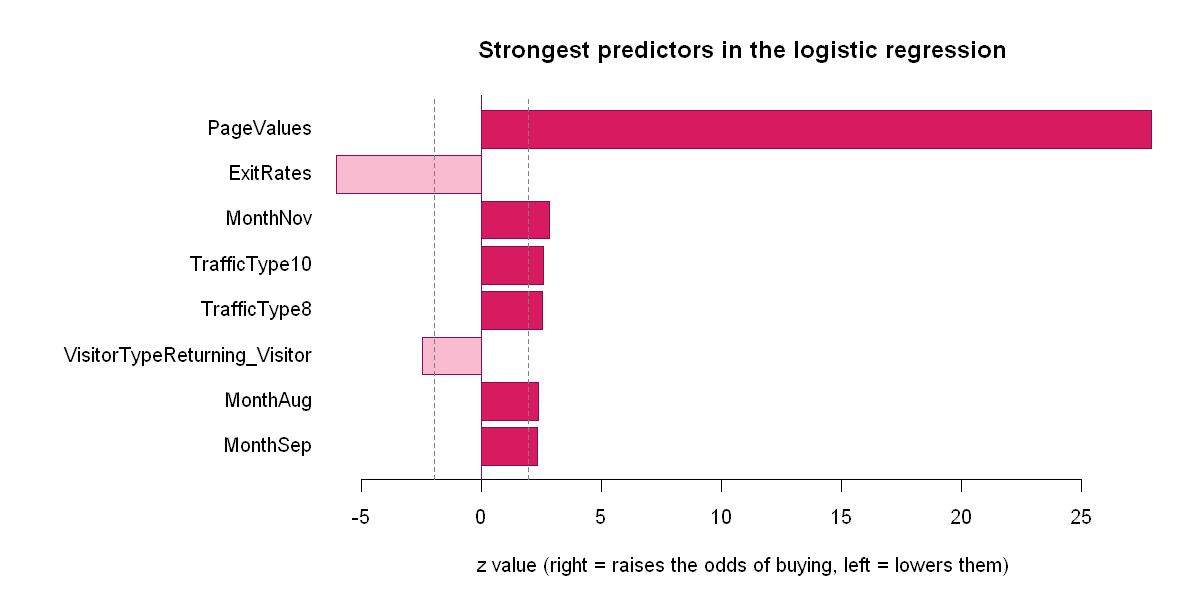

In [6]:
# Part 3(a)
fit_log = suppressWarnings(                   # hide a harmless warning that some sessions get probabilities very close to 0 or 1
  glm(buy ~ . - buy_f, data = train, family = binomial))   # logistic regression using every predictor (buy_f is a copy of the outcome, so leave it out)
summary(fit_log)                              # coefficient table

z_vals = summary(fit_log)$coefficients[-1, "z value"]   # z value of every predictor (drop the intercept)
top8 = z_vals[order(abs(z_vals), decreasing = TRUE)][1:8]   # the 8 strongest predictors, positive or negative
par(mar = c(5, 14, 4, 2))                     # wider left margin for the predictor names
barplot(rev(top8), horiz = TRUE, las = 1,     # horizontal bar chart, strongest at the top
        col = rev(ifelse(top8 > 0, "#D81B60", "#F8BBD0")), border = "#880E4F",   # dark pink raises the odds, light pink lowers them
        xlab = "z value (right = raises the odds of buying, left = lowers them)",   # x axis label
        main = "Strongest predictors in the logistic regression")   # plot title
abline(v = c(-1.96, 1.96), lty = 2, col = "grey50")   # dashed lines: bars past these are significant at the 5% level
abline(v = 0, col = "#880E4F")                # line at zero
par(mar = c(5, 4, 4, 2))                      # reset the margins

I fit a logistic regression using all 17 predictors on the 8,631 training sessions.
The model has 56 coefficients, because each category variable, like month or browser, gets one coefficient for every group except a baseline group.
The residual deviance dropped from about 7519.7 with no predictors to about 4997.2 with all of them, so the predictors explain a good part of who buys.
The AIC is about 5109.2. I use this later to compare against a smaller model.
PageValues is by far the strongest predictor, with a z value of about 27.9 and a p-value below 2 × 10^-16.
Its coefficient is about 0.082, so each 1 point increase in page value multiplies the odds of a purchase by about e^0.082 = 1.085, holding everything else fixed.
For a 10 point increase, the odds are multiplied by about 2.26.
ExitRates is also very significant, with a coefficient of about -18.3 and a p-value of about 1.4 × 10^-9.
Since exit rate is a proportion, a 0.01 increase multiplies the odds of a purchase by about e^-0.183 = 0.83, a drop of about 17%.
So visitors who leave from more of the pages they view are less likely to buy.
Compared to February, most months have higher odds of a purchase. November has the largest effect, with a coefficient of about 2.94 and a p-value of about 0.004.
July through October are also significant at the 5% level.
Returning visitors have lower odds of buying than new visitors, with a coefficient of about -0.26 and a p-value of about 0.015.
Two traffic sources, types 8 and 10, also have significantly higher odds of a purchase.
Most other predictors are not significant, including the administrative and informational page counts and times, bounce rate, special day, operating system, browser, and region.
Bounce rate is likely not significant because it is very similar to exit rate, which already carries that information.
Since many predictors add little, this model is a good candidate for reduction in Part 5.
My bar chart shows the 8 strongest predictors in the model, ranked by the size of their z value.
Bars to the right raise the odds of a purchase, and bars to the left lower them.
The dashed lines are at about plus and minus 1.96, so any bar past them is significant at the 5% level.
PageValues is far ahead of everything else, with a z value of about 27.9.
ExitRates and returning visitors are the only two of the top 8 that lower the odds of buying.
November, August, and September raise the odds compared to February, and so do traffic types 8 and 10.

**b)** Decision tree.

n= 8631 

node), split, n, loss, yval, (yprob)
      * denotes terminal node

 1) root 8631 1360 0 (0.84242846 0.15757154)  
   2) PageValues< 0.9448195 6732  280 0 (0.95840761 0.04159239) *
   3) PageValues>=0.9448195 1899  819 1 (0.43127962 0.56872038)  
     6) BounceRates>=8.11e-05 1064  459 0 (0.56860902 0.43139098)  
      12) Month=Feb,May,June,Jul,Aug,Sep,Oct,Dec 606  187 0 (0.69141914 0.30858086) *
      13) Month=Mar,Nov 458  186 1 (0.40611354 0.59388646)  
        26) ExitRates>=0.02350767 159   71 0 (0.55345912 0.44654088) *
        27) ExitRates< 0.02350767 299   98 1 (0.32775920 0.67224080) *
     7) BounceRates< 8.11e-05 835  214 1 (0.25628743 0.74371257) *

[1] "PageValues"  "BounceRates" "Month"       "ExitRates"

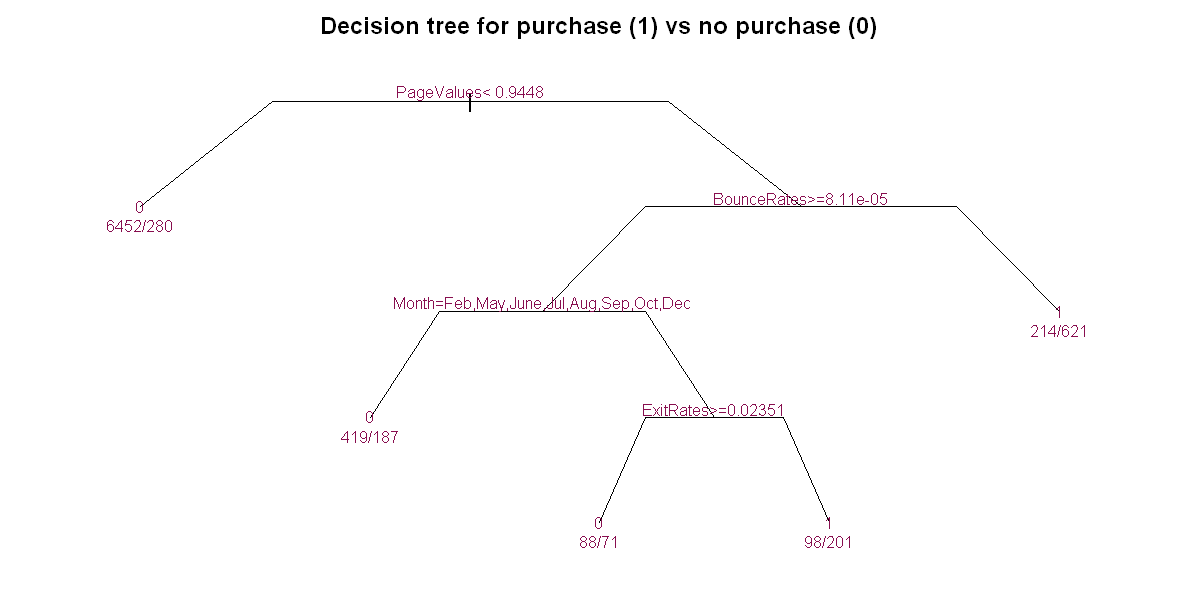

In [7]:
# Part 3(b)
train$buy_f = factor(train$buy)               # outcome as a category for the tree and forest
test$buy_f = factor(test$buy)                 # same for the testing data
fit_tree = rpart(buy_f ~ . - buy, data = train, method = "class")   # classification tree using every predictor
fit_tree                                      # print the splits of the tree
tree_vars = unique(as.character(fit_tree$frame$var[fit_tree$frame$var != "<leaf>"]))   # predictors the tree actually used
tree_vars                                     # show them
par(mar = c(1, 1, 2, 1))                      # small margins for the tree drawing
plot(fit_tree, uniform = TRUE, branch = 0.6, margin = 0.08, col = "#AD1457",   # draw the tree in deep pink
     main = "Decision tree for purchase (1) vs no purchase (0)")
text(fit_tree, use.n = TRUE, pretty = 0, cex = 0.8, col = "#880E4F")   # add the split rules and counts, with full month names
par(mar = c(5, 4, 4, 2))                      # reset the margins

I fit a classification tree, which predicts a purchase by asking a series of yes or no questions about each session.
The tree starts with all 8,631 training sessions, where about 15.8% ended in a purchase.
The first and most important split is on page value.
Sessions with a page value below about 0.94 go left. There are 6,732 of them, and only about 4.2% bought, so the tree predicts no purchase.
Sessions with a page value of about 0.94 or more go right. There are 1,899 of them, and about 56.9% bought.
For those higher page value sessions, the next split is on bounce rate.
Sessions with a bounce rate of almost exactly 0 had 835 visits, and about 74.4% bought, so the tree predicts a purchase.
Sessions with a higher bounce rate had 1,064 visits, and about 43.1% bought, so the tree splits them again by month.
In February, May, June, July, August, September, October, and December, 606 sessions had about a 30.9% purchase rate, so the tree predicts no purchase.
In March and November, 458 sessions had about a 59.4% purchase rate, so the tree splits them one more time by exit rate.
If the exit rate is below about 0.024, 299 sessions had about a 67.2% purchase rate, so the tree predicts a purchase.
If the exit rate is about 0.024 or higher, 159 sessions had about a 44.7% purchase rate, so the tree predicts no purchase.
The tree ends with 5 final groups and uses only 4 of the 17 predictors: page value, bounce rate, month, and exit rate.
This means the tree already does its own kind of model reduction, since it ignores predictors that do not help.
The tree is easy to explain, because each prediction comes from a short list of simple rules.
It agrees with the logistic regression that page value is the most important predictor by far.

**c)** Random forest with 500 trees.

In [8]:
# Part 3(c)
set.seed(5206)                                # fix the random seed so the forest is the same every time this cell runs
fit_rf = randomForest(buy_f ~ . - buy, data = train,   # random forest using every predictor
                      ntree = 500, importance = TRUE)  # 500 trees, and keep track of variable importance
fit_rf                                        # out-of-bag error and confusion table on the training data


Call:
 randomForest(formula = buy_f ~ . - buy, data = train, ntree = 500,      importance = TRUE) 
               Type of random forest: classification
                     Number of trees: 500
No. of variables tried at each split: 4

        OOB estimate of  error rate: 9.62%
Confusion matrix:
     0   1 class.error
0 6991 280  0.03850915
1  550 810  0.40441176

I fit a random forest with 500 decision trees, using all 17 predictors.
Each tree is built on a random sample of the training sessions, and at each split it only looks at a random 4 of the 17 predictors.
This makes the trees different from each other. The forest then lets all 500 trees vote, and the majority vote is the prediction.
Averaging many different trees usually makes the forest more accurate and more stable than a single tree.
I set a random seed right before fitting, so the forest comes out the same every time I run the notebook.
The out-of-bag (OOB) error rate is about 9.62%.
Each tree leaves out about a third of the training sessions, and the OOB error checks each session using only the trees that did not see it.
So the OOB error is like a built-in test on the training data, and it suggests the forest is right about 90.4% of the time.
That is better than the 84.2% I would get by always guessing “no purchase” on the training data.
The confusion table shows where the forest makes mistakes.
Of the 7,271 training sessions with no purchase, the forest correctly predicted 6,991 and wrongly flagged 280 as purchases, an error rate of only about 3.9%.
Of the 1,360 sessions with a purchase, the forest correctly caught 810 but missed 550, an error rate of about 40.4%.
So the forest is very good at spotting visitors who will not buy, but it misses about 4 out of 10 buyers.
This happens because buyers are only about 16% of the data, so the forest leans toward predicting “no purchase.”
I check how the forest does on the testing data in Part 4.

## Part 4: Predictions and accuracy on the testing data

**a)** Predict the probability of a purchase for every testing session with each model. Show 10 testing sessions (5 that ended in a purchase and 5 that did not) with their actual outcome and each model's prediction (cutoff 0.50).

In [9]:
# Part 4(a)
test$p_log = predict(fit_log, newdata = test, type = "response")      # logistic regression probability of a purchase
test$p_tree = predict(fit_tree, newdata = test, type = "prob")[, "1"] # decision tree probability of a purchase
test$p_rf = predict(fit_rf, newdata = test, type = "prob")[, "1"]     # random forest probability of a purchase

set.seed(5206)                                # fix the random seed so the same 10 example sessions are picked every time
show_rows = c(sample(which(test$buy == 1), 5),   # 5 random testing sessions that ended in a purchase
              sample(which(test$buy == 0), 5))   # 5 random testing sessions that did not
ten = test[show_rows, ]                       # those 10 sessions
data.frame(Actual = ten$buy,                  # what really happened (1 = purchase)
           Logistic_p = round(ten$p_log, 3), Logistic_pred = as.integer(ten$p_log >= 0.5),   # logistic probability and prediction
           Tree_p = round(ten$p_tree, 3), Tree_pred = as.integer(ten$p_tree >= 0.5),         # tree probability and prediction
           Forest_p = round(ten$p_rf, 3), Forest_pred = as.integer(ten$p_rf >= 0.5),         # forest probability and prediction
           row.names = NULL)

Actual,Logistic_p,Logistic_pred,Tree_p,Tree_pred,Forest_p,Forest_pred
<int>,<dbl>,<int>,<dbl>,<int>,<dbl>,<int>
1,0.069,0,0.309,0,0.304,0
1,1.000,1,0.744,1,0.696,1
1,0.092,0,0.744,1,0.410,0
1,0.303,0,0.744,1,0.516,1
1,0.914,1,0.744,1,0.946,1
0,0.052,0,0.042,0,0.146,0
0,0.002,0,0.042,0,0.002,0
0,0.139,0,0.042,0,0.096,0
0,0.055,0,0.042,0,0.012,0


I used each model to predict the probability of a purchase for every one of the 3,699 testing sessions, which the models never saw during training.
If a model’s probability was 0.50 or higher, I counted that as a predicted purchase.
To show some examples, I picked 10 testing sessions at random: 5 that ended in a purchase and 5 that did not.
I set a random seed, so the same 10 sessions are picked every time.
All three models correctly predicted no purchase for all 5 sessions that did not buy.
For these 5 sessions, the probabilities were all low, mostly under 0.15.
The models did less well on the 5 sessions that did buy.
Two buyers were caught by all three models, with probabilities like 0.914 and 0.946.
One buyer was missed by all three models, with probabilities of only about 0.07 to 0.31.
For the other two buyers, the models disagreed. The tree caught both, the forest caught one, and the logistic regression missed both.
In total, the logistic regression got 7 of the 10 right, the random forest got 8, and the decision tree got 9.
The tree’s probabilities only take a few values, like 0.042, 0.309, and 0.744, because every session that lands in the same final group of the tree gets the same probability.
The logistic regression and the forest give a different probability for each session, so they can show more detail.
These 10 sessions are only examples, and half of them are buyers, which is more than the 15% in the real data.
So I should not judge the models from these 10 alone. I compare them on all 3,699 testing sessions in Parts 4(b) and 4(c).

**b)** Accuracy and confusion tables at a 0.50 cutoff. Compare with a baseline that always predicts "no purchase."

In [10]:
# Part 4(b)
acc = function(p, y) mean(as.integer(p >= 0.5) == y)   # function for the share of correct predictions at 0.50
round(c(Baseline_always_no = mean(test$buy == 0),   # accuracy if we always guess no purchase
        Logistic = acc(test$p_log, test$buy),       # logistic regression accuracy
        Tree = acc(test$p_tree, test$buy),          # decision tree accuracy
        Forest = acc(test$p_rf, test$buy)), 3)      # random forest accuracy

list(                                         # confusion tables, labeled by model
  Logistic = table(Actual = test$buy, Predicted = as.integer(test$p_log >= 0.5)),   # logistic regression
  Tree = table(Actual = test$buy, Predicted = as.integer(test$p_tree >= 0.5)),      # decision tree
  Forest = table(Actual = test$buy, Predicted = as.integer(test$p_rf >= 0.5)))      # random forest

Baseline_always_no           Logistic               Tree             Forest 
             0.852              0.896              0.899              0.911

$Logistic
      Predicted
Actual    0    1
     0 3084   67
     1  319  229

$Tree
      Predicted
Actual    0    1
     0 3008  143
     1  232  316

$Forest
      Predicted
Actual    0    1
     0 3038  113
     1  217  331


I checked how often each model’s prediction was correct on the 3,699 testing sessions, using a cutoff of 0.50.
A baseline that always guesses “no purchase” would be right about 85.2% of the time, since that many testing sessions did not buy.
The logistic regression was right about 89.6% of the time.
The decision tree was right about 89.9% of the time.
The random forest was right about 91.1% of the time, which is the best of the three.
All three models beat the baseline, but only by about 4 to 6 percentage points.
This is why accuracy alone can be misleading here. The baseline is already high because most visitors do not buy.
The confusion tables show where each model goes wrong.
There were 548 buyers and 3,151 non-buyers in the testing data.
The logistic regression caught 229 of the 548 buyers, about 42%, and wrongly flagged only 67 non-buyers, about 2%.
The decision tree caught 316 buyers, about 58%, and wrongly flagged 143 non-buyers, about 5%.
The random forest caught 331 buyers, about 60%, and wrongly flagged 113 non-buyers, about 4%.
So the random forest catches the most buyers while keeping false alarms low.
The logistic regression is the most careful. It rarely flags a non-buyer, but it misses more than half of the real buyers.
All three models miss a large share of buyers, because buyers are only about 15% of the data and the 0.50 cutoff is hard to reach.
A lower cutoff would catch more buyers, but it would also flag more non-buyers. The ROC curves in Part 4(c) show this trade-off at every cutoff.

**c)** ROC curves and AUC for each model.

Logistic     Tree   Forest 
   0.883    0.865    0.932

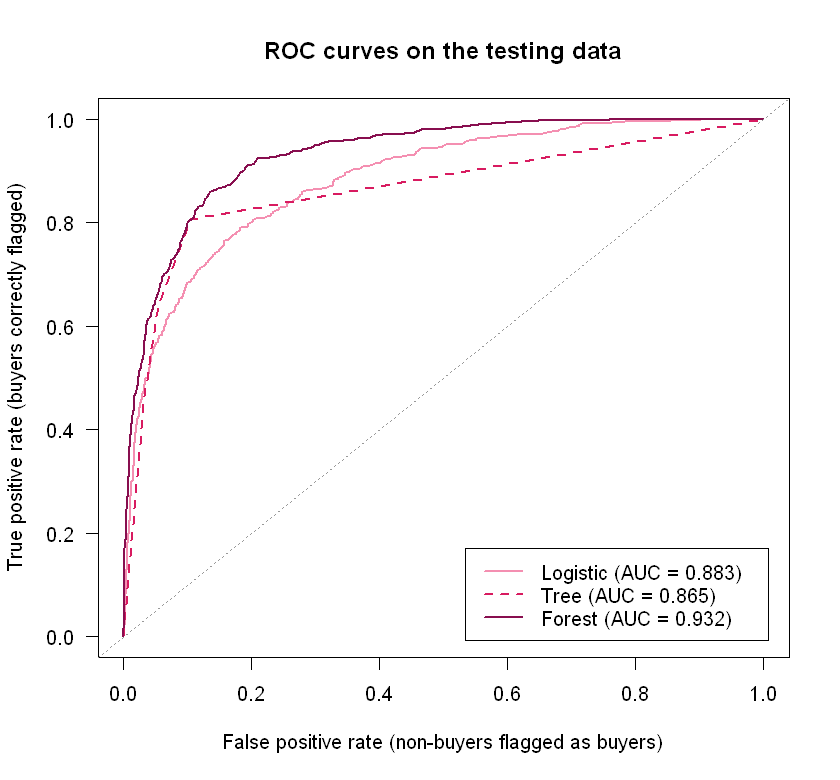

In [11]:
# Part 4(c)
roc_xy = function(p, y) {                     # function that returns the points of an ROC curve
  cuts = sort(unique(c(0, p, 1)), decreasing = TRUE)   # every possible cutoff
  tpr = sapply(cuts, function(k) mean(p[y == 1] >= k)) # true positive rate: buyers correctly flagged
  fpr = sapply(cuts, function(k) mean(p[y == 0] >= k)) # false positive rate: non-buyers wrongly flagged
  data.frame(fpr = fpr, tpr = tpr)
}
auc = function(p, y) {                        # function for the area under the ROC curve
  r = rank(p)                                 # rank all probabilities together
  n1 = sum(y == 1); n0 = sum(y == 0)          # number of buyers and non-buyers
  (sum(r[y == 1]) - n1 * (n1 + 1) / 2) / (n1 * n0)   # chance a random buyer gets a higher score than a random non-buyer
}
aucs = c(Logistic = auc(test$p_log, test$buy),   # logistic regression AUC
         Tree = auc(test$p_tree, test$buy),      # decision tree AUC
         Forest = auc(test$p_rf, test$buy))      # random forest AUC
round(aucs, 3)                                # show the three AUC values

r_log = roc_xy(test$p_log, test$buy)          # ROC points for logistic regression
r_tree = roc_xy(test$p_tree, test$buy)        # ROC points for the decision tree
r_rf = roc_xy(test$p_rf, test$buy)            # ROC points for the random forest
options(repr.plot.width = 7, repr.plot.height = 6.5)   # make this plot close to square so the legend has room
plot(r_log$fpr, r_log$tpr, type = "l", lwd = 2, col = "#F48FB1", las = 1,   # light pink ROC curve for logistic regression
     xlab = "False positive rate (non-buyers flagged as buyers)",
     ylab = "True positive rate (buyers correctly flagged)",
     main = "ROC curves on the testing data")
lines(r_tree$fpr, r_tree$tpr, lwd = 2, col = "#D81B60", lty = 2)   # dark pink dashed ROC curve for the tree
lines(r_rf$fpr, r_rf$tpr, lwd = 2, col = "#880E4F")                # deepest pink ROC curve for the forest
abline(0, 1, col = "grey60", lty = 3)         # grey dotted line = coin flip (AUC 0.5)
legend("bottomright", lwd = 2, lty = c(1, 2, 1), inset = 0.03,   # legend with each model's AUC, moved in from the edge
       col = c("#F48FB1", "#D81B60", "#880E4F"), bg = "white",
       legend = paste0(names(aucs), " (AUC = ", round(aucs, 3), ")"))
options(repr.plot.width = 10, repr.plot.height = 5)   # back to the normal plot size for later cells

An ROC curve shows how well a model separates buyers from non-buyers at every possible cutoff, not just 0.50.
The x axis is the false positive rate, the share of non-buyers wrongly flagged as buyers.
The y axis is the true positive rate, the share of real buyers correctly flagged.
A perfect model would go straight up to the top left corner, and a coin flip would follow the grey dotted diagonal line.
All three curves rise steeply and stay well above the diagonal, so all three models are much better than guessing.
The AUC is the area under each curve. It is the chance that a randomly chosen buyer gets a higher predicted probability than a randomly chosen non-buyer.
The random forest has the highest AUC, about 0.932.
The logistic regression has an AUC of about 0.883.
The decision tree has the lowest AUC, about 0.865.
The forest’s curve is on top almost everywhere, so it ranks buyers above non-buyers best at nearly every cutoff.
For example, the forest catches about 80% of buyers while flagging only about 10% of non-buyers.
The tree’s curve is made of a few straight pieces, because the tree only gives a few different probabilities, one for each of its final groups.
That is why the tree does well at one cutoff but falls behind the other models across the full range.
The logistic regression starts below the tree but passes it once the false positive rate goes above about 0.2.
Using AUC, the random forest is the best model, which matches its highest accuracy in Part 4(b).
AUC is more useful than accuracy here, because accuracy was close to the 85.2% baseline for all three models, while AUC shows a clearer difference between them.

## Part 5: Model reduction

**a)** Reduce the logistic regression with backward stepwise selection using AIC. Compare the full and reduced models on the testing data.

In [12]:
# Part 5(a)
fit_log_small = suppressWarnings(              # hide a harmless warning about some fitted probabilities being very close to 0 or 1
  step(fit_log, direction = "backward", trace = 0))   # remove predictors one at a time while AIC goes down
formula(fit_log_small)                        # predictors kept in the reduced model
setdiff(attr(terms(fit_log), "term.labels"),  # predictors removed
        attr(terms(fit_log_small), "term.labels"))
c(AIC_full = AIC(fit_log), AIC_reduced = AIC(fit_log_small))   # AIC before and after

test$p_log_small = predict(fit_log_small, newdata = test, type = "response")   # reduced model probabilities
round(c(Full_accuracy = acc(test$p_log, test$buy),           # full model accuracy
        Reduced_accuracy = acc(test$p_log_small, test$buy),  # reduced model accuracy
        Full_AUC = auc(test$p_log, test$buy),                # full model AUC
        Reduced_AUC = auc(test$p_log_small, test$buy)), 3)   # reduced model AUC

buy ~ ProductRelated + ProductRelated_Duration + ExitRates + 
    PageValues + Month + TrafficType + VisitorType + Weekend

[1] "Administrative"          "Administrative_Duration"
[3] "Informational"           "Informational_Duration" 
[5] "BounceRates"             "SpecialDay"             
[7] "OperatingSystems"        "Browser"                
[9] "Region"

AIC_full AIC_reduced 
   5109.237    5081.939

Full_accuracy Reduced_accuracy         Full_AUC      Reduced_AUC 
           0.896            0.897            0.883            0.885

To reduce the logistic regression, I used backward stepwise selection with AIC.
This method starts with the full model that uses all 17 predictors.
At each step, it tries removing each predictor one at a time and checks the AIC.
It removes the predictor whose removal lowers the AIC the most.
It keeps going until removing any more predictors would make the AIC go up.
A lower AIC means a better balance between fitting the data well and keeping the model simple.
The method removed 9 predictors: administrative pages, administrative time, informational pages, informational time, bounce rate, special day, operating system, browser, and region.
It kept 8 predictors: product pages, time on product pages, exit rate, page value, month, traffic type, visitor type, and weekend.
Most of the removed predictors were not significant in the full model in Part 3(a), so this makes sense.
Bounce rate was removed because exit rate already carries most of the same information.
The AIC went down from about 5109.2 to about 5081.9, so the reduced model is better by this measure.
On the testing data, the full model had an accuracy of about 89.6% and the reduced model had about 89.7%.
The full model had an AUC of about 0.883 and the reduced model had about 0.885.
So the reduced model predicts just as well, even slightly better, while using about half as many predictors.
This means the 9 removed predictors were not adding useful information, and the simpler model is easier to explain.

**b)** Reduce the random forest using variable importance. Keep the 6 most important predictors, refit, and compare.

PageValues               ExitRates ProductRelated_Duration 
                  826.1                   192.7                   183.4 
         ProductRelated                   Month             BounceRates 
                  156.7                   134.2                   124.7 
Administrative_Duration             TrafficType                  Region 
                  122.0                   109.8                   105.7 
         Administrative  Informational_Duration                 Browser 
                   89.7                    56.5                    54.1 
       OperatingSystems           Informational             VisitorType 
                   39.2                    36.6                    24.6 
                Weekend              SpecialDay 
                   18.6                     6.0

[1] "PageValues"              "ExitRates"              
[3] "ProductRelated_Duration" "ProductRelated"         
[5] "Month"                   "BounceRates"

Full_accuracy Reduced_accuracy         Full_AUC      Reduced_AUC 
           0.911            0.905            0.932            0.922

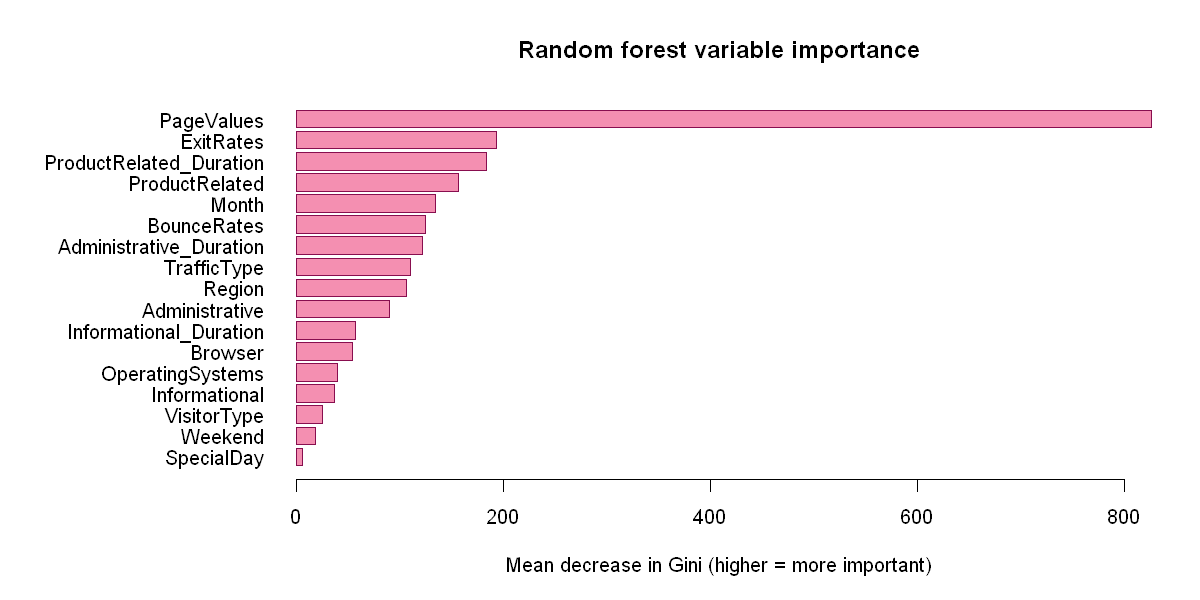

In [13]:
# Part 5(b)
imp = importance(fit_rf)[, "MeanDecreaseGini"]   # how much each predictor helps the forest
imp = sort(imp, decreasing = TRUE)            # most important first
round(imp, 1)                                 # show the importance scores
par(mar = c(5, 12, 4, 2))                     # wider left margin for the variable names
barplot(rev(imp), horiz = TRUE, las = 1, col = "#F48FB1", border = "#880E4F",   # horizontal bar chart of importance
        xlab = "Mean decrease in Gini (higher = more important)",
        main = "Random forest variable importance")
par(mar = c(5, 4, 4, 2))                      # reset the margins

top6 = names(imp)[1:6]                        # the 6 most important predictors
top6                                          # show them
set.seed(5206)                                # fix the random seed so the reduced forest is the same every time
fit_rf_small = randomForest(reformulate(top6, response = "buy_f"), data = train,   # refit the forest with only those 6
                            ntree = 500)
test$p_rf_small = predict(fit_rf_small, newdata = test, type = "prob")[, "1"]   # reduced forest probabilities
round(c(Full_accuracy = acc(test$p_rf, test$buy),            # full forest accuracy
        Reduced_accuracy = acc(test$p_rf_small, test$buy),   # reduced forest accuracy
        Full_AUC = auc(test$p_rf, test$buy),                 # full forest AUC
        Reduced_AUC = auc(test$p_rf_small, test$buy)), 3)    # reduced forest AUC

To reduce the random forest, I used variable importance.
The forest measures how much each predictor helps it separate buyers from non-buyers, using the mean decrease in Gini. A higher score means the predictor is more useful.
Page value is by far the most important predictor, with a score of about 826.1. That is more than 4 times the next one.
The next most important are exit rate (about 192.7), time on product pages (about 183.4), number of product pages (about 156.7), month (about 134.2), and bounce rate (about 124.7).
The least important are special day (about 6.0), weekend (about 18.6), and visitor type (about 24.6).
I kept the 6 most important predictors and refit the forest using only those 6.
I set a random seed before refitting, so the reduced forest comes out the same every time.
The full forest with 17 predictors had an accuracy of about 91.1% and an AUC of about 0.932.
The reduced forest with 6 predictors had an accuracy of about 90.5% and an AUC of about 0.922.
So the reduced forest lost only about 0.6 percentage points of accuracy and 0.01 of AUC, while using 11 fewer predictors.
This is a small loss for a much simpler model.
The forest and the stepwise logistic regression mostly agree. Both keep page value, exit rate, product pages, time on product pages, and month.
They disagree on a few predictors. The forest keeps bounce rate, while the logistic regression drops it. The logistic regression keeps visitor type and weekend, while the forest ranks them low.
This happens because the two methods measure usefulness in different ways, so the exact list of predictors depends on the model.
Choosing 6 predictors was my own cutoff to keep the model small. The biggest drop in importance is after page value, so the exact number of predictors to keep is a judgment call.

**c)** Final comparison of all models on the testing data.

In [14]:
# Part 5(c)
n_vars = function(m) length(attr(terms(m), "term.labels"))   # function that counts the predictors in a model
final = data.frame(
  Model = c("Logistic (full)", "Logistic (reduced)", "Decision tree", "Random forest (full)", "Random forest (top 6)"),
  Predictors = c(n_vars(fit_log), n_vars(fit_log_small), length(tree_vars),
                 n_vars(fit_rf), n_vars(fit_rf_small)),       # number of predictors each model uses
  Accuracy = c(acc(test$p_log, test$buy), acc(test$p_log_small, test$buy), acc(test$p_tree, test$buy),
               acc(test$p_rf, test$buy), acc(test$p_rf_small, test$buy)),   # accuracy at 0.50
  AUC = c(auc(test$p_log, test$buy), auc(test$p_log_small, test$buy), auc(test$p_tree, test$buy),
          auc(test$p_rf, test$buy), auc(test$p_rf_small, test$buy)))         # area under the ROC curve
final$Accuracy = round(final$Accuracy, 3)     # round for display
final$AUC = round(final$AUC, 3)               # round for display
final                                         # show the final table

Model,Predictors,Accuracy,AUC
<chr>,<int>,<dbl>,<dbl>
Logistic (full),17,0.896,0.883
Logistic (reduced),8,0.897,0.885
Decision tree,4,0.899,0.865
Random forest (full),17,0.911,0.932
Random forest (top 6),6,0.905,0.922


This table compares all five models on the 3,699 testing sessions.
The full random forest is the best model, with the highest accuracy, about 91.1%, and the highest AUC, about 0.932.
The reduced random forest is close behind, with about 90.5% accuracy and an AUC of about 0.922, while using only 6 predictors instead of 17.
The reduced logistic regression did slightly better than the full one, with about 89.7% accuracy and an AUC of about 0.885, using 8 predictors instead of 17.
The decision tree uses only 4 predictors and has good accuracy, about 89.9%, but the lowest AUC, about 0.865.
All five models beat the baseline of always guessing “no purchase,” which is right about 85.2% of the time.
Reducing the models removed many predictors with very little loss, and for the logistic regression, no loss at all.
This shows that a small set of predictors carries most of the useful information.
Page value, exit rate, product page activity, and month were important in every model.
So the answer to my question is yes: website session data can be used to train a model that predicts whether a visit ends in a purchase, with an AUC above 0.93 for the best model.
There are some limits.
At a 0.50 cutoff, even the best model misses about 4 out of 10 buyers, because buyers are only about 15% of the data.
Page value is by far the strongest predictor, and it is calculated by Google Analytics from pages that tend to come before a purchase, so it may partly reflect purchase behavior that has already started.
The data comes from one unnamed online store over one year, and the exact year is not reported, so the results may not hold for other stores or for today’s shoppers.